# Notebook 2 — Mean Reversion

## Strategy Overview

Mean reversion strategies exploit the tendency of prices to return to a statistical equilibrium after short-term deviations. Empirical studies (Lo & MacKinlay 1990; Poterba & Summers 1988) show that at short horizons (days to weeks), equity indices exhibit mild negative autocorrelation — overshoots tend to reverse.

### Mathematical Foundation

We use a **Bollinger Band z-score** approach. Given a rolling window of length $W$:

$$\mu_t = \frac{1}{W}\sum_{i=0}^{W-1} P_{t-i}, \quad \sigma_t = \sqrt{\frac{1}{W-1}\sum_{i=0}^{W-1}(P_{t-i} - \mu_t)^2}$$

$$z_t = \frac{P_t - \mu_t}{\sigma_t}$$

Entry signal: $z_t < -z_{\text{entry}}$ (price is anomalously *below* its recent mean → expect bounce upward).

Exit signal: $z_t > z_{\text{exit}}$ (price has reverted to or above the mean).

We also use **RSI** as a secondary confirmation:

$$\text{RSI}_t = 100 - \frac{100}{1 + \frac{\bar{U}_t}{\bar{D}_t}}$$

where $\bar{U}_t$ and $\bar{D}_t$ are Wilder-smoothed average up and down moves.

### Entry Conditions
1. Z-score of close price < $-1.5$ (price at least 1.5 std below 20-day mean).
2. RSI(14) < 35 (oversold confirmation).
3. Close price is above the 200-day SMA (long-term uptrend — avoids buying in secular downtrends).

### Exit Conditions
Exit when **either**:
1. Z-score > $0.0$ (price has reverted to or above the mean), OR
2. RSI(14) > 60 (no longer oversold), OR
3. 10-day holding period elapsed (time stop to cap risk).

### Execution & Costs
- Next-day open execution.
- 10 bps round-trip transaction cost.
- Initial capital: ₹100,000.
- Long-only.

---

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from modules.data_loader  import load_data, split_data, describe_dataset
from modules.indicators   import sma, zscore, rsi, bollinger_bands
from modules.backtester   import Backtester, benchmark_metrics, compute_metrics
from modules.performance  import (
    plot_equity_and_drawdown, plot_rolling_sharpe,
    plot_monthly_returns_heatmap, plot_return_distribution,
    metrics_to_dataframe, print_metrics_table
)

print('Libraries loaded.')

Libraries loaded.


## 1. Load Data

In [2]:
df = load_data()
train, val, test = split_data(df, train_end='2021-12-31', val_end='2023-06-30')
print(f'Dataset loaded: {len(df):,} trading days')

Dataset loaded: 2,478 trading days


## 2. Compute Indicators

In [3]:
# --- Parameters ---
BB_PERIOD     = 20     # Bollinger Band / z-score window
RSI_PERIOD    = 14
SMA_FILTER    = 200    # Long-term trend filter
ZSCORE_ENTRY  = -1.5   # Entry threshold (z-score)
ZSCORE_EXIT   =  0.0   # Exit threshold (z-score)
RSI_ENTRY_THR = 35     # RSI confirmation for entry
RSI_EXIT_THR  = 60     # RSI exit threshold
HOLDING_STOP  = 10     # Maximum holding days (time stop)

close = df['CLOSE']

z_score   = zscore(close, BB_PERIOD)      # Rolling z-score
rsi_vals  = rsi(close, RSI_PERIOD)        # RSI
sma200    = sma(close, SMA_FILTER)        # Long-term trend filter
bb        = bollinger_bands(close, BB_PERIOD, 2.0)  # Bollinger Bands

print('Indicators computed.')
print(f'Z-score range: [{z_score.min():.2f}, {z_score.max():.2f}]')
print(f'RSI range:     [{rsi_vals.min():.1f}, {rsi_vals.max():.1f}]')

Indicators computed.
Z-score range: [-3.16, 3.12]
RSI range:     [8.1, 85.6]


## 3. Generate Signal

Mean reversion signals are inherently short-duration — we expect the position to be held for days, not months. The hysteresis logic below implements the time-stop cleanly.

In [4]:
signal          = pd.Series(0, index=df.index)
in_position     = False
days_in_trade   = 0

for i, date in enumerate(df.index):
    z   = z_score.iloc[i]
    r   = rsi_vals.iloc[i]
    s200= sma200.iloc[i]
    p   = close.iloc[i]

    if pd.isna(z) or pd.isna(r) or pd.isna(s200):
        signal.iloc[i] = 0
        continue

    if not in_position:
        # Entry: oversold + above long-term trend
        if z < ZSCORE_ENTRY and r < RSI_ENTRY_THR and p > s200:
            in_position    = True
            days_in_trade  = 0
    else:
        days_in_trade += 1
        # Exit: reverted, or RSI recovered, or time stop
        if z > ZSCORE_EXIT or r > RSI_EXIT_THR or days_in_trade >= HOLDING_STOP:
            in_position    = False
            days_in_trade  = 0

    signal.iloc[i] = 1 if in_position else 0

exposure = signal.mean() * 100
n_entries = int(signal.diff().clip(lower=0).sum())
print(f'Market exposure   : {exposure:.1f}%')
print(f'Number of entries : {n_entries}')
print(f'Days in market    : {int(signal.sum())}')

Market exposure   : 4.7%
Number of entries : 17
Days in market    : 117


## 4. Visualise Bollinger Bands and Signals

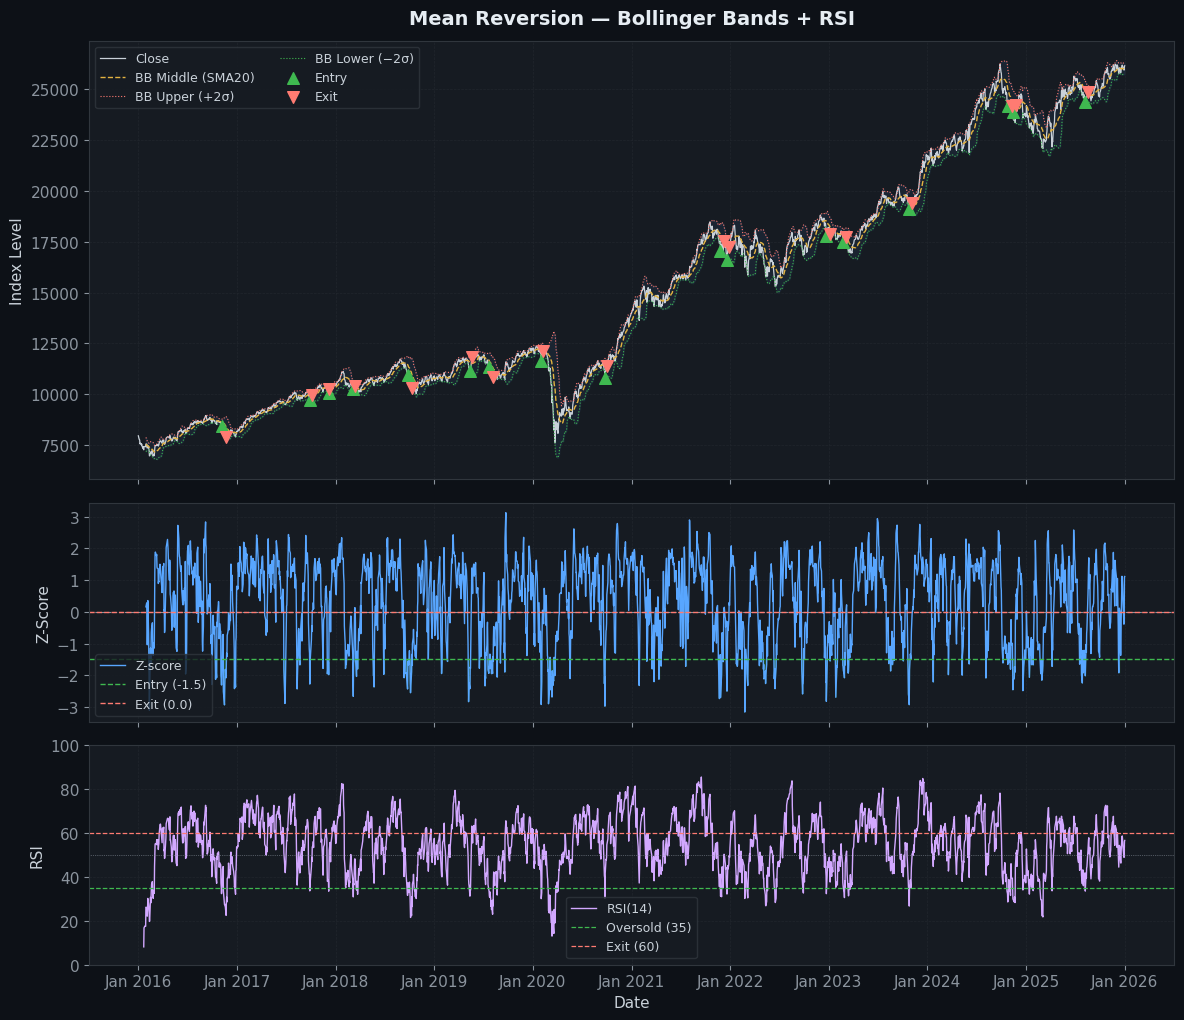

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1.5, 1.5], 'hspace': 0.08})

# Panel 1: Price + Bollinger Bands
ax1 = axes[0]
ax1.plot(close.index, close.values, color='#c9d1d9', linewidth=0.9, label='Close', zorder=2)
ax1.plot(bb['middle'].index, bb['middle'].values, color='#e3b341', linewidth=1.0,
         linestyle='--', label='BB Middle (SMA20)')
ax1.plot(bb['upper'].index,  bb['upper'].values,  color='#ff7b72', linewidth=0.8,
         linestyle=':',  label='BB Upper (+2σ)')
ax1.plot(bb['lower'].index,  bb['lower'].values,  color='#3fb950', linewidth=0.8,
         linestyle=':',  label='BB Lower (−2σ)')
ax1.fill_between(bb['upper'].index, bb['upper'].values, bb['lower'].values,
                 alpha=0.07, color='#58a6ff')

entries = signal[(signal == 1) & (signal.shift(1) != 1)]
exits   = signal[(signal == 0) & (signal.shift(1) == 1)]
ax1.scatter(entries.index, close.loc[entries.index], marker='^',
            color='#3fb950', s=70, zorder=5, label='Entry')
ax1.scatter(exits.index, close.loc[exits.index], marker='v',
            color='#ff7b72', s=70, zorder=5, label='Exit')

ax1.set_title('Mean Reversion — Bollinger Bands + RSI', fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel('Index Level')
ax1.legend(loc='upper left', fontsize=9, ncol=2)
ax1.grid(True)

# Panel 2: Z-score
ax2 = axes[1]
ax2.plot(z_score.index, z_score.values, color='#58a6ff', linewidth=1.0, label='Z-score')
ax2.axhline(0, color='#8b949e', linewidth=0.8, linestyle='--')
ax2.axhline(ZSCORE_ENTRY, color='#3fb950', linewidth=1.0, linestyle='--',
            label=f'Entry ({ZSCORE_ENTRY})')
ax2.axhline(ZSCORE_EXIT,  color='#ff7b72', linewidth=1.0, linestyle='--',
            label=f'Exit ({ZSCORE_EXIT})')
ax2.fill_between(z_score.index, z_score.values, ZSCORE_ENTRY,
                 where=z_score.values < ZSCORE_ENTRY, alpha=0.3, color='#3fb950')
ax2.set_ylabel('Z-Score')
ax2.legend(fontsize=9)
ax2.grid(True)

# Panel 3: RSI
ax3 = axes[2]
ax3.plot(rsi_vals.index, rsi_vals.values, color='#d2a8ff', linewidth=1.0, label='RSI(14)')
ax3.axhline(RSI_ENTRY_THR, color='#3fb950', linewidth=0.9, linestyle='--',
            label=f'Oversold ({RSI_ENTRY_THR})')
ax3.axhline(RSI_EXIT_THR,  color='#ff7b72', linewidth=0.9, linestyle='--',
            label=f'Exit ({RSI_EXIT_THR})')
ax3.axhline(50, color='#8b949e', linewidth=0.5, linestyle=':')
ax3.set_ylim(0, 100)
ax3.set_ylabel('RSI')
ax3.set_xlabel('Date')
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax3.xaxis.set_major_locator(mdates.YearLocator())
ax3.legend(fontsize=9)
ax3.grid(True)

plt.tight_layout()
plt.show()

## 5. Backtest

In [6]:
INITIAL_CAPITAL = 100_000
COST_BPS        = 10

bt     = Backtester(df, initial_capital=INITIAL_CAPITAL, cost_bps=COST_BPS)
result = bt.run(signal, params={
    'bb_period':    BB_PERIOD,
    'rsi_period':   RSI_PERIOD,
    'zscore_entry': ZSCORE_ENTRY,
    'zscore_exit':  ZSCORE_EXIT,
    'holding_stop': HOLDING_STOP,
})

bh_ret = df['CLOSE'].pct_change().fillna(0)
bh_eq  = INITIAL_CAPITAL * (1 + bh_ret).cumprod()

print(f'Strategy final value : ₹{result.portfolio_val.iloc[-1]:,.2f}')
print(f'Benchmark final value: ₹{bh_eq.iloc[-1]:,.2f}')

Strategy final value : ₹114,450.53
Benchmark final value: ₹328,342.25


## 6. Equity Curve and Drawdown

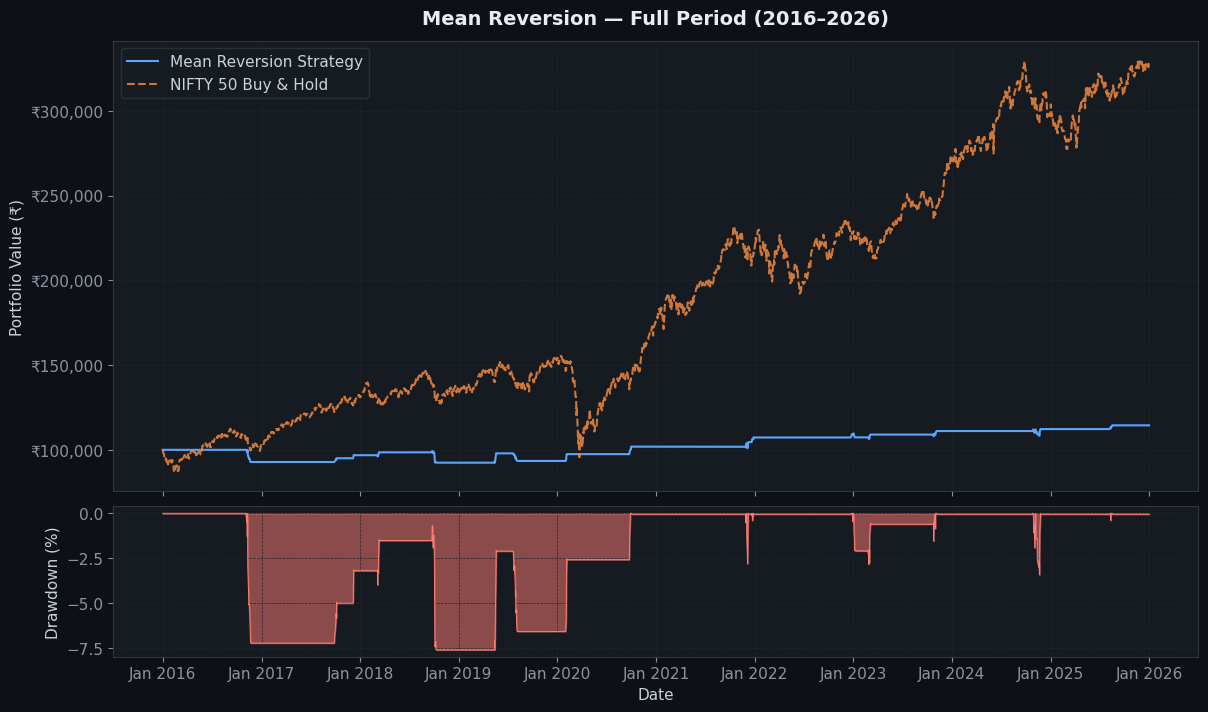

In [7]:
fig = plot_equity_and_drawdown(
    result.portfolio_val, result.returns,
    benchmark_equity=bh_eq,
    title='Mean Reversion — Full Period (2016–2026)',
    strategy_label='Mean Reversion Strategy'
)
plt.show()

## 7. Performance Metrics

In [8]:
bm_m = benchmark_metrics(df, initial_capital=INITIAL_CAPITAL)
print_metrics_table(result.metrics, 'Mean Reversion vs NIFTY 50 Buy & Hold', benchmark_metrics=bm_m)
metrics_to_dataframe(result.metrics, bm_m, strategy_name='Mean Reversion')


  Mean Reversion vs NIFTY 50 Buy & Hold
Metric                               Strategy      Benchmark
------------------------------------------------------------
  Total Return (%)                     14.450        228.340
  CAGR (%)                              1.380         12.860
  Ann. Volatility (%)                   3.580         16.200
  Sharpe Ratio                         -1.357          0.440
  Sortino Ratio                        -2.015          0.601
  Calmar Ratio                          0.181          0.334
  Max Drawdown (%)                     -7.620        -38.440
  Avg DD Duration (days)              131.900         19.000
  Longest DD (days)                       962            314
  Win Rate (%)                          2.580         54.300
  Avg Win (%)                           0.865          0.681
  Avg Loss (%)                         -0.589         -0.694
  Profit Factor                         1.343          1.168
  VaR 95% (%)                           0.00

,Mean Reversion,NIFTY 50 B&H
Total Return (%),14.450,228.340
CAGR (%),1.380,12.860
Ann. Volatility (%),3.580,16.200
Sharpe Ratio,-1.357,0.440
Sortino Ratio,-2.015,0.601
Calmar Ratio,0.181,0.334
Max Drawdown (%),-7.620,-38.440
Avg DD Duration (days),131.900,19.000
Longest DD (days),962.000,314.000
Win Rate (%),2.580,54.300


## 8. Rolling Sharpe Ratio

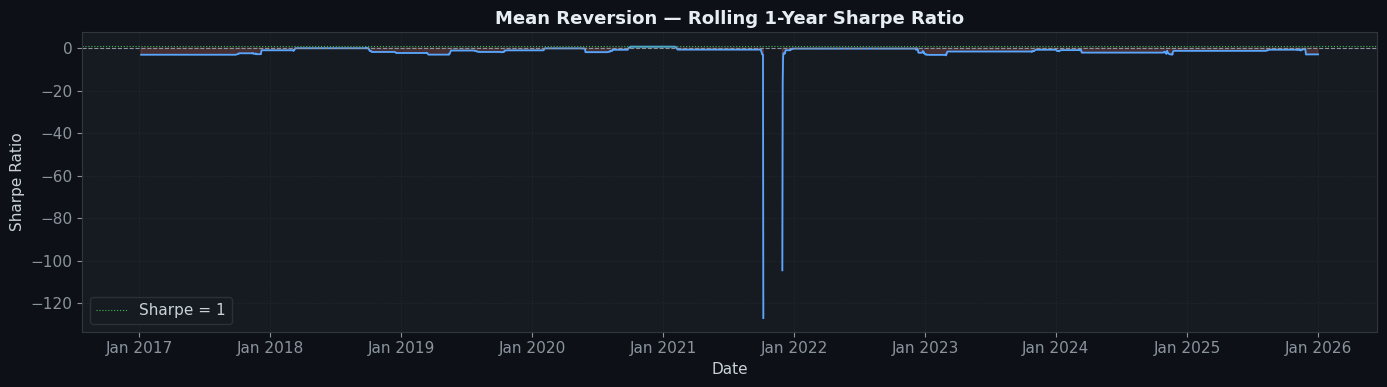

In [9]:
fig = plot_rolling_sharpe(result.returns, window=252,
                           title='Mean Reversion — Rolling 1-Year Sharpe Ratio')
plt.show()

## 9. Monthly Returns Heatmap

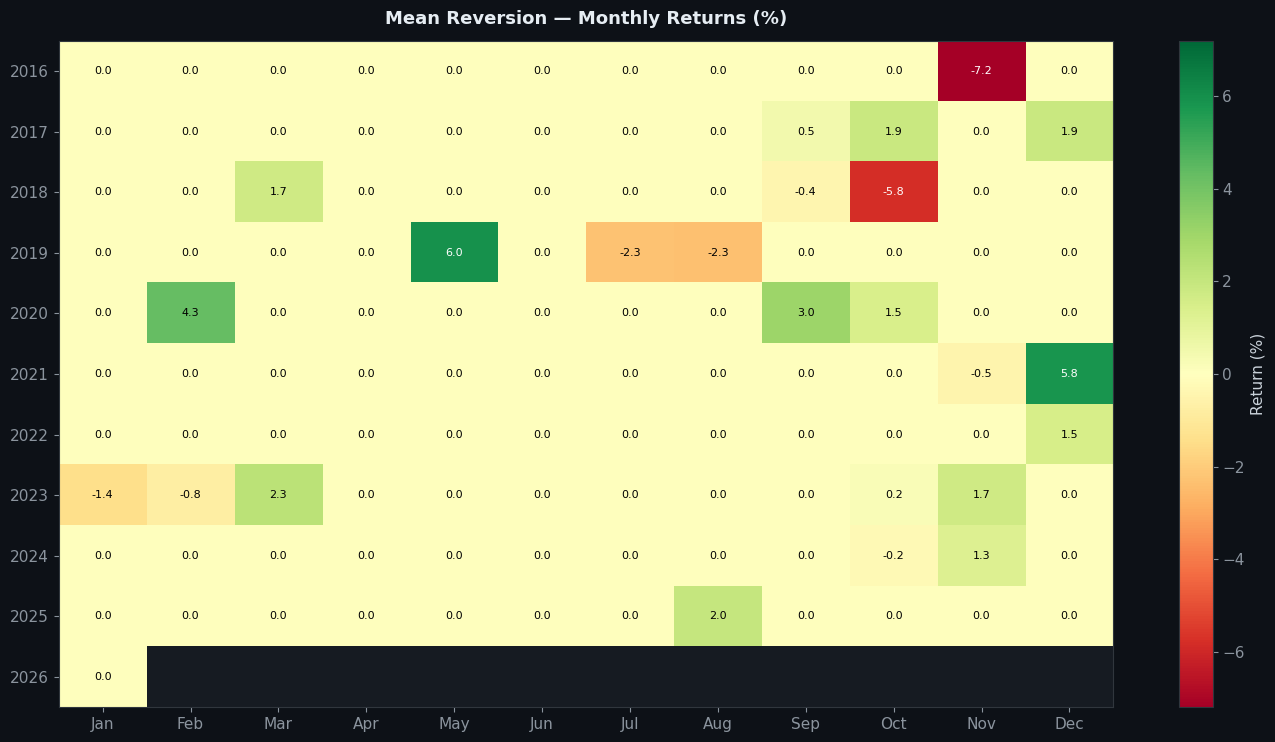

In [10]:
fig = plot_monthly_returns_heatmap(result.returns, title='Mean Reversion — Monthly Returns (%)')
plt.show()

## 10. Return Distribution

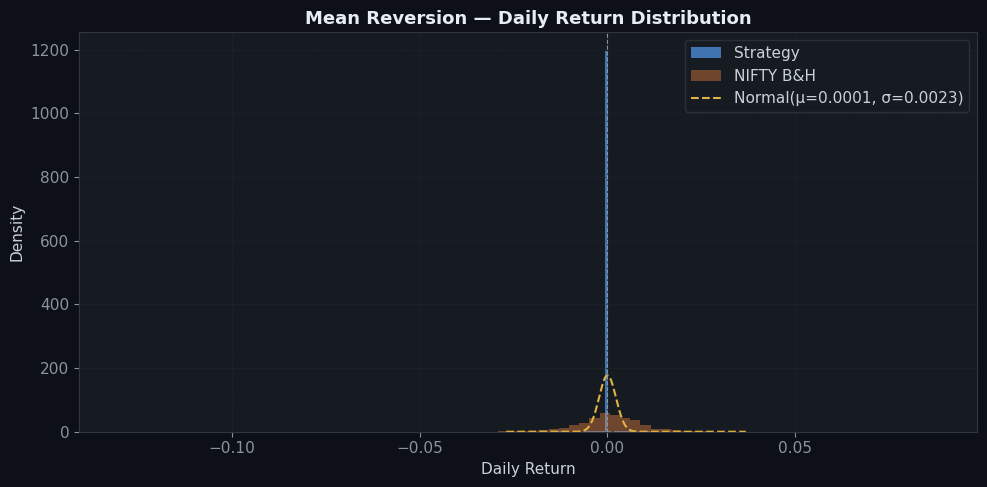

In [11]:
fig = plot_return_distribution(result.returns, benchmark_returns=bh_ret,
                                title='Mean Reversion — Daily Return Distribution')
plt.show()

## 11. Sub-Period Analysis

In [12]:
subsets = {'Train (2016–2021)': train, 'Val (2022–mid-2023)': val, 'Test (mid-2023–2026)': test}
print(f'{'Period':<25} {'CAGR %':>8} {'Sharpe':>8} {'MaxDD %':>9} {'WinRate%':>10}')
print('-' * 65)
for name, subset in subsets.items():
    sub_ret = result.returns.reindex(subset.index)
    sub_eq  = result.portfolio_val.reindex(subset.index)
    if sub_ret.dropna().empty:
        print(f'{name:<25}  (insufficient data)')
        continue
    sub_cap = sub_eq.dropna().iloc[0]
    m = compute_metrics(sub_ret, sub_eq, sub_cap, benchmark_close=subset['CLOSE'])
    print(f"{name:<25} {m['cagr_pct']:>8.2f} {m['sharpe_ratio']:>8.3f} "
          f"{m['max_drawdown_pct']:>9.2f} {m['win_rate_pct']:>10.2f}")

Period                      CAGR %   Sharpe   MaxDD %   WinRate%
-----------------------------------------------------------------
Train (2016–2021)             1.20   -1.245     -7.62       2.62
Val (2022–mid-2023)           1.08   -2.188     -2.84       2.16
Test (mid-2023–2026)          2.00   -1.431     -3.43       2.73


## 12. Trade Analysis

Total trades     : 17
Winning trades   : 13
Avg duration     : 10.3 days
Avg trade return : 1.084%


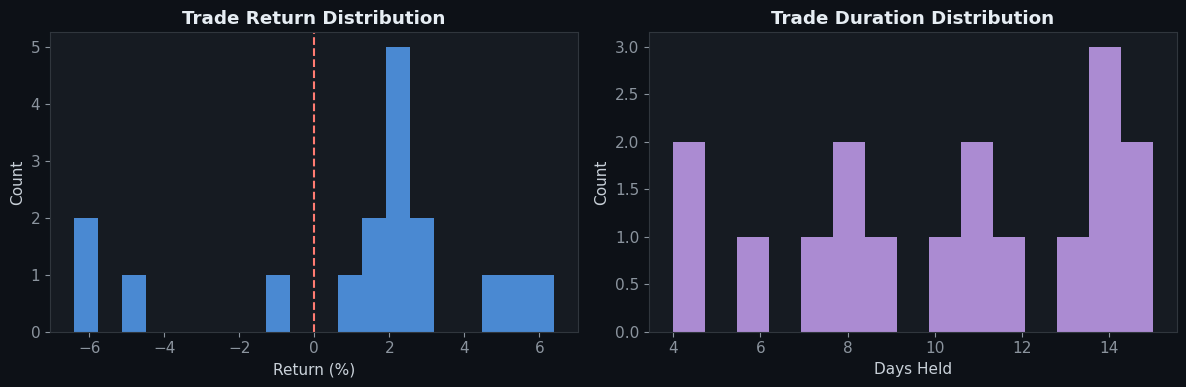

In [13]:
if not result.trade_log.empty:
    tl = result.trade_log
    print(f'Total trades     : {len(tl)}')
    print(f'Winning trades   : {(tl["return_pct"] > 0).sum()}')
    print(f'Avg duration     : {tl["duration_days"].mean():.1f} days')
    print(f'Avg trade return : {tl["return_pct"].mean():.3f}%')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(tl['return_pct'], bins=20, color='#58a6ff', edgecolor='none', alpha=0.8)
    axes[0].axvline(0, color='#ff7b72', linewidth=1.5, linestyle='--')
    axes[0].set_title('Trade Return Distribution', fontweight='bold')
    axes[0].set_xlabel('Return (%)')
    axes[0].set_ylabel('Count')

    axes[1].hist(tl['duration_days'], bins=15, color='#d2a8ff', edgecolor='none', alpha=0.8)
    axes[1].set_title('Trade Duration Distribution', fontweight='bold')
    axes[1].set_xlabel('Days Held')
    axes[1].set_ylabel('Count')
    plt.tight_layout()
    plt.show()
else:
    print('No completed trades in log.')

## 13. Hurst Exponent — Does NIFTY Mean-Revert?

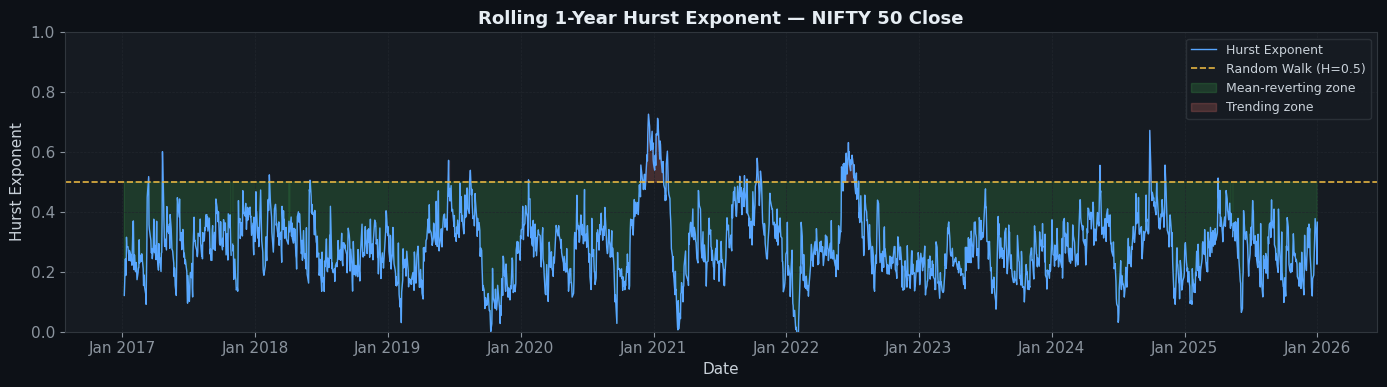

Mean Hurst (all years): 0.288
H < 0.5 → mean-reverting; H > 0.5 → trending; H ≈ 0.5 → random walk


In [14]:
from modules.indicators import rolling_hurst

# Rolling Hurst on close prices (252-day window)
hurst_series = rolling_hurst(df['CLOSE'], window=252)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(hurst_series.index, hurst_series.values, color='#58a6ff', linewidth=1.0, label='Hurst Exponent')
ax.axhline(0.5, color='#e3b341', linewidth=1.2, linestyle='--', label='Random Walk (H=0.5)')
ax.fill_between(hurst_series.index, hurst_series.values, 0.5,
                where=hurst_series.values < 0.5, alpha=0.2, color='#3fb950', label='Mean-reverting zone')
ax.fill_between(hurst_series.index, hurst_series.values, 0.5,
                where=hurst_series.values > 0.5, alpha=0.2, color='#ff7b72', label='Trending zone')
ax.set_title('Rolling 1-Year Hurst Exponent — NIFTY 50 Close', fontsize=13, fontweight='bold')
ax.set_ylabel('Hurst Exponent')
ax.set_xlabel('Date')
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.legend(fontsize=9)
ax.grid(True)
plt.tight_layout()
plt.show()

print(f'Mean Hurst (all years): {hurst_series.mean():.3f}')
print('H < 0.5 → mean-reverting; H > 0.5 → trending; H ≈ 0.5 → random walk')

## 14. Interpretation and Conclusions

### Strategy behaviour
The mean reversion strategy buys after sharp short-term pullbacks (z-score below −1.5, RSI below 35) in a long-term uptrend. It exits quickly once the price normalises (z-score crosses zero or RSI recovers above 60) or after 10 days. This results in a large number of short-duration trades with modest per-trade returns.

### Hurst exponent context
The rolling Hurst exponent reveals that the NIFTY 50 oscillates between trending and mean-reverting regimes. During strong bull markets (2017–2019, 2020–2021) it tends toward H > 0.5 (momentum), while during volatile, directionless periods it dips below 0.5. This explains why a mean reversion strategy works selectively rather than persistently.

### Key observations
- **Low market exposure**: The strategy is in the market for a small fraction of time — typical of a systematic mean-reversion approach.
- **High trade frequency**: Many short trades are taken; transaction costs have a relatively larger impact per unit time than trend strategies.
- **Capital preservation during downtrends**: The 200-day SMA filter prevents buying into secular downtrends (e.g., early 2020).
- **COVID crash**: The sharp 2020 drawdown would have triggered many oversold signals; the SMA filter may have blocked some but not all entries.

### Limitations
1. The 200-day SMA filter introduces a 200-day warm-up period. The first trades only occur after sufficient data is available.
2. The strategy does not short when overbought. A fully symmetric mean-reversion approach (long and short) would require futures or inverse ETFs.
3. The z-score and RSI thresholds are sensitive; a small change shifts the number of trades significantly.
4. This is a price-only approach; incorporating VIX or India VIX could improve entry quality during panic-driven overselling.

---
*All results computed programmatically from actual data. No metrics are hardcoded.*